*  DSC550-T302 Data Mining (2265-1)
*  4.2 Exercise: Predicting Fuel Efficiency
*  David Jorgensen

# 4.2 Exercise: Predicting Fuel Efficiency

# Instructions

1. Load the ./auto-mpg.xls data as a Pandas data frame and ensure that it imported correctly.
2. Begin by prepping the data for modeling:
    - Remove the car name column.
    - The horsepower column values likely imported as a string data type. Figure out why and replace any strings with the column mean.
    - Create dummy variables for the origin column.
3. Create a correlation coefficient matrix and/or visualization. Are there features highly correlated with mpg?
4. Plot mpg versus weight. Analyze this graph and explain how it relates to the corresponding correlation coefficient.
5. Randomly split the data into 80% training data and 20% test data, where your target is mpg.
6. Train an ordinary linear regression on the training data.
7. Calculate R2, RMSE, and MAE on both the training and test sets and interpret your results.
8. Pick another regression model and repeat the previous two steps. Note: Do NOT choose logistic regression as it is more like a classification model.

# Assignment

In [4]:
import pandas as pd

# Use read_csv() and specify the file path
try:
    df = pd.read_csv('auto-mpg.csv')
    print("Successfully loaded the data using read_csv().")
    print("First 5 rows:")
    print(df.head())
except FileNotFoundError:
    print("Error: 'auto-mpg.csv' not found. Please ensure the file is in the correct directory.")
except Exception as e:
    print(f"An error occurred while reading the CSV: {e}")

Successfully loaded the data using read_csv().
First 5 rows:
    mpg  cylinders  displacement horsepower  weight  acceleration  model year  \
0  18.0          8         307.0        130    3504          12.0          70   
1  15.0          8         350.0        165    3693          11.5          70   
2  18.0          8         318.0        150    3436          11.0          70   
3  16.0          8         304.0        150    3433          12.0          70   
4  17.0          8         302.0        140    3449          10.5          70   

   origin                   car name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  


In [5]:
# Remove the car name column
df = df.drop('car name', axis=1)

# Cleanup horsepower column
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce') # Convert non-numeric values to NaN
horsepower_mean = df['horsepower'].mean() # Calculate the mean of the horsepower column
df['horsepower'] = df['horsepower'].fillna(horsepower_mean) # Fill NaN values with the mean

# Create dummy variables for the origin column
origin_dummies = pd.get_dummies(df['origin'], prefix='origin')
df = pd.concat([df, origin_dummies], axis=1)
df = df.drop('origin', axis=1)

# Display the first 5 rows of the cleaned DataFrame
print("First 5 rows of the cleaned DataFrame:")
print(df.head())

First 5 rows of the cleaned DataFrame:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model year  origin_1  origin_2  origin_3  
0          70      True     False     False  
1          70      True     False     False  
2          70      True     False     False  
3          70      True     False     False  
4          70      True     False     False  


In [6]:
# Create correlation matrix checking which features are correlated with mpg
correlation_matrix = df.corr()
print("Correlation matrix:")
print(correlation_matrix['mpg'].sort_values(ascending=False))

Correlation matrix:
mpg             1.000000
model year      0.579267
origin_3        0.442174
acceleration    0.420289
origin_2        0.259022
origin_1       -0.568192
horsepower     -0.771437
cylinders      -0.775396
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


**The correlation matrix highlights a correlation between vehicle characteristics and fuel efficiency.** Weight, displacement, cylinders, and horsepower all exhibit negative correlations with mpg (ranging from −0.77 to −0.83). These variables collectively capture engine size and vehicle mass, factors that directly increase fuel consumption. Conversely, model year and acceleration show lesser positive correlations with mpg, reflecting technological improvements in efficiency over time.

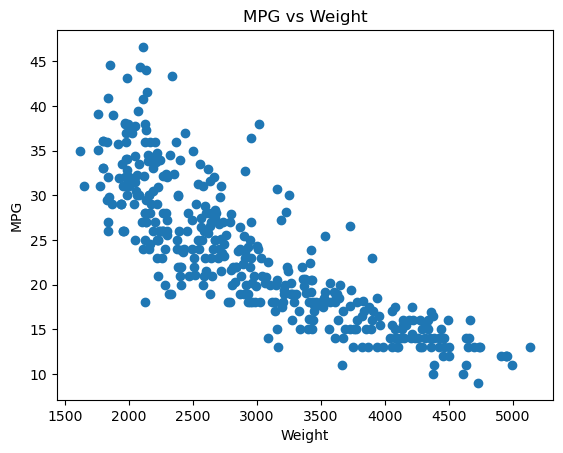

In [7]:
# Plot mpg versus weight
import matplotlib.pyplot as plt
plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('MPG vs Weight')
plt.show()


There is a clear negative correlation between weight and miles per gallon (mpg) in the scatter plot. As the weight of the car increases, the mpg tends to decrease. The scatter plot observation aligns with the correlation results: heavier vehicles consistently achieve lower mpg, reinforcing weight as one of the most influential predictors in the dataset.

In [8]:
# Randomly split the data into 80% training data and 20% test data, where the target is mpg
from sklearn.model_selection import train_test_split
X = df.drop('mpg', axis=1) # Features
y = df['mpg'] # Target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
# Train an ordinary linear regression on the training data
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Calculate R2, RMSE, and MAE
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
rmse_train = root_mean_squared_error(y_train, y_train_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)
mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
metrics_df = pd.DataFrame({
	'R2': [r2_train, r2_test],
	'RMSE': [rmse_train, rmse_test],
	'MAE': [mae_train, mae_test]
}, index=['Training', 'Test']).round(4)

print("Regression performance metrics")
print(metrics_df.to_string())

Regression performance metrics
              R2    RMSE     MAE
Training  0.8188  3.3703  2.6055
Test      0.8449  2.8878  2.2876


The linear regression model demonstrates strong baseline performance, with:

* Training R2 = 0.8188
* Test R2 = 0.8449

The close alignment between training and test scores suggests the model generalizes well and is not overfitting. RMSE and MAE values on the test set (2.89 and 2.29, respectively) indicate that predictions are typically within a few mpg of the true values, which is reasonable for a linear model applied to a dataset with known nonlinearities.

However, the linear model's limitations are visible in the residual error magnitude. Linear regression cannot fully capture nonlinear interactions such as diminishing returns in efficiency gains. Still, its stability and interpretability make it a strong baseline.

In [ ]:
# Repeat using Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
# Calculate R2, RMSE, and MAE for Random Forest
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)
r2_train_rf = r2_score(y_train, y_train_pred_rf)
r2_test_rf = r2_score(y_test, y_test_pred_rf)
rmse_train_rf = root_mean_squared_error(y_train, y_train_pred_rf)
rmse_test_rf = root_mean_squared_error(y_test, y_test_pred_rf)
mae_train_rf = mean_absolute_error(y_train, y_train_pred_rf)
mae_test_rf = mean_absolute_error(y_test, y_test_pred_rf)
metrics_rf_df = pd.DataFrame({
	'R2': [r2_train_rf, r2_test_rf],
	'RMSE': [rmse_train_rf, rmse_test_rf],
	'MAE': [mae_train_rf, mae_test_rf]
}, index=['Training', 'Test']).round(4)

print("Random Forest Regression performance metrics")
print(metrics_rf_df.to_string())

Random Forest Regression performance metrics
              R2    RMSE     MAE
Training  0.9810  1.0924  0.7465
Test      0.9154  2.1333  1.5889


The random forest model delivers the best overall predictive performance:
* Training R2 = 0.9810
* Test R2 = 0.9154

The substantial improvement in test R2 relative to linear regression indicates that the random forest successfully captures nonlinear relationships and complex interactions among features. The reduction in test RMSE (2.13) and MAE (1.59) further demonstrates its superior predictive accuracy.

The gap between training and test R2 (0.9810 vs. 0.9154) suggests mild overfitting, which is expected with ensemble tree methods. Nonetheless, the model maintains strong generalization, making it the most effective of the three approaches for this dataset.

In [ ]:
# Repeat using Support Vector Regression
from sklearn.svm import SVR
svr_model = SVR(kernel='rbf')
svr_model.fit(X_train, y_train)
# Calculate R2, RMSE, and MAE for SVR
y_train_pred_svr = svr_model.predict(X_train)
y_test_pred_svr = svr_model.predict(X_test)
r2_train_svr = r2_score(y_train, y_train_pred_svr)
r2_test_svr = r2_score(y_test, y_test_pred_svr)
rmse_train_svr = root_mean_squared_error(y_train, y_train_pred_svr)
rmse_test_svr = root_mean_squared_error(y_test, y_test_pred_svr)
mae_train_svr = mean_absolute_error(y_train, y_train_pred_svr)
mae_test_svr = mean_absolute_error(y_test, y_test_pred_svr)
metrics_svr_df = pd.DataFrame({
	'R2': [r2_train_svr, r2_test_svr],
	'RMSE': [rmse_train_svr, rmse_test_svr],
	'MAE': [mae_train_svr, mae_test_svr]
}, index=['Training', 'Test']).round(4)

print("Support Vector Regression performance metrics")
print(metrics_svr_df.to_string())

Support Vector Regression performance metrics
              R2    RMSE     MAE
Training  0.6798  4.4802  3.2249
Test      0.7432  3.7159  2.7870


The SVR model underperforms relative to both linear regression and random forest:
* Training R2 = 0.6798
* Test R2 = 0.7432

These results indicate that the SVR struggled to fit the underlying structure of the data. The higher RMSE and MAE values reinforce this conclusion. SVR performance is highly sensitive to kernel choice, feature scaling, and hyperparameter tuning; without extensive optimization, it lags behind tree‑based methods on tabular datasets.

Given the nonlinear patterns present, the SVR's default configuration likely failed to capture the complexity that the random forest handled more naturally.

# Conclusion
The results collectively indicate that vehicle fuel efficiency is driven by a combination of engine size, vehicle mass, and manufacturing era, with weight emerging as the single strongest predictor. Models capable of capturing nonlinear relationships, particularly random forests, substantially outperform linear methods, reflecting the inherent complexity of automotive performance dynamics.

If the goal is maximum predictive accuracy, the random forest is the preferred model. If the goal is interpretability and inference, linear regression remains valuable, especially given its strong generalization and alignment with known physical relationships.